# Base sales from a Bayesian MMM: which part to use, or skip it

**Audience:** analysts who have read guide 06 and whose short-term media has carryover and saturation.

**What this notebook does:** guide 06 built base sales with a UCM, which can only fit short-term effects that are linear and land in the same week. Real performance media carries over and saturates, so the short-term model has to be a Bayesian MMM. This notebook uses PyMC-Marketing and asks two questions:

- **Which part of the MMM should the VECM get?** Total sales minus the MMM's contributions, or the MMM's own time-varying trend (its baseline).
- **Is the MMM needed at all?** The alternative is one step: total sales straight into the VECM, with the short-term drivers in the sales equation.

**Requires** `pymc-marketing` (not a dependency of this package): `uv pip install pymc-marketing` or `pip install pymc-marketing`. Tested with version 1.3.0.

In [1]:
# Sampling configuration, as in the other guides.
FAST_SAMPLING = True

if FAST_SAMPLING:
    DRAWS, TUNE, CHAINS = 1000, 1000, 2
    MMM_DRAWS, MMM_TUNE = 500, 500
else:
    DRAWS, TUNE, CHAINS = 2000, 1000, 4
    MMM_DRAWS, MMM_TUNE = 1000, 1000

LEVEL = 0.90  # every interval in this notebook is a 90% interval
TAILS = (100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2)

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymc_extras.prior import Prior
from pymc_marketing.hsgp_kwargs import HSGPKwargs
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation

from bayesian_vecm import BayesianVECM, simulate_brand_data

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)
COLOURS = {
    "true_base": "black",
    "mmm_minus": "#2a78d6",
    "mmm_trend": "#eb6834",
    "one_step": "#3a9e5f",
}
LABELS = {
    "true_base": "true base",
    "mmm_minus": "MMM: total minus contributions",
    "mmm_trend": "MMM: its trend",
    "one_step": "one step: total sales into the VECM",
}
SPEC = {"k_ar_diff": 1, "coint_rank": 2, "deterministic": "co"}
SALES, AWARE, CONS = "organic_sales", "brand_awareness", "brand_consideration"
CHANNELS = ["paid_search", "paid_social", "brand_spend"]
PERIOD = 365.25 / 7.0
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

/home/claude/pmm/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. The data

As in guide 06, but now the short-term effects carry over and saturate:

- **Adstock decays** of 0.3 (brand spend's short-term hit and paid search) and 0.5 (paid social).
- **Logistic saturation** of 3 (paid search) and 2 (paid social).
- **Weekly noise** outside the brand system of 2% of the reference level.

In [3]:
NOISE = 0.02
SALES_ADSTOCK = {"brand_spend": 0.3, "paid_search": 0.3, "paid_social": 0.5}
SALES_SATURATION = {"paid_search": 3.0, "paid_social": 2.0}

data = simulate_brand_data(
    total_sales=True,
    sales_noise=NOISE,
    sales_adstock=SALES_ADSTOCK,
    sales_saturation=SALES_SATURATION,
)
endog, exog, truth = data.endog, data.exog, data.truth
total = data.sales["total_sales"]
parts = truth.sales_parts
pd.DataFrame(
    {"average £ a week": parts.mean(), "share of total sales": parts.mean() / total.mean()}
).round({"average £ a week": 0, "share of total sales": 3})

,average £ a week,share of total sales
base,1465.0,0.885
brand_spend,0.0,0.000
paid_search,111.0,0.067
paid_social,71.0,0.043
promo,9.0,0.006
seasonality,0.0,0.000
noise,-2.0,-0.001


## 2. The MMM

A standard PyMC-Marketing set-up: geometric adstock, logistic saturation, two yearly Fourier modes, promo as a control, and a **time-varying intercept**. The intercept is a Hilbert-space Gaussian process (HSGP), the MMM's trend. Its lengthscale sets how fast it can move; the prior here has a mean of 78 weeks. The fit takes about two minutes.

In [4]:
LENGTHSCALE = 78  # prior mean for the trend's lengthscale, in weeks

spend = exog["brand_spend"]
mmm_data = pd.DataFrame(
    {
        "date": total.index,
        "paid_search": data.sales_drivers["paid_search"].to_numpy(),
        "paid_social": data.sales_drivers["paid_social"].to_numpy(),
        # Channels must be non-negative: shift brand spend to start at zero.
        "brand_spend": (spend - spend.min()).to_numpy(),
        "promo": data.sales_drivers["promo"].to_numpy(),
    }
)
y = pd.Series(total.to_numpy(), name="y")

mmm = MMM(
    date_column="date",
    channel_columns=CHANNELS,
    control_columns=["promo"],
    adstock=GeometricAdstock(l_max=8),
    saturation=LogisticSaturation(),
    yearly_seasonality=2,
    time_varying_intercept=True,
    model_config={
        # Positive priors on the scaled target. With the defaults the fit was
        # not identified: a negative intercept and channels worth £3,400 a week.
        "intercept": Prior("Gamma", mu=0.6, sigma=0.3),
        "saturation_beta": Prior("HalfNormal", sigma=0.15, dims="channel"),
        "gamma_control": Prior("Normal", mu=0, sigma=0.2, dims="control"),
        "intercept_tvp_config": HSGPKwargs(
            m=100, eta_lam=1.0, ls_mu=LENGTHSCALE, ls_sigma=LENGTHSCALE / 4
        ),
    },
)
mmm.build_model(mmm_data, y)
mmm.add_original_scale_contribution_variable(
    var=[
        "channel_contribution",
        "control_contribution",
        "intercept_contribution",
        "yearly_seasonality_contribution",
    ]
)
mmm.fit(
    mmm_data,
    y,
    draws=MMM_DRAWS,
    tune=MMM_TUNE,
    chains=CHAINS,
    target_accept=0.9,
    nuts_sampler="nutpie",
    random_seed=14,
    progressbar=False,
)
print(f"MMM divergences: {int(mmm.idata['sample_stats']['diverging'].sum())}")

NUTS[nutpie]: [gamma_fourier, intercept_latent_process_raw_hsgp_coefs_offset, intercept_latent_process_raw_eta, intercept_latent_process_raw_ls, intercept_baseline, gamma_control, adstock_alpha, saturation_lam, saturation_beta, y_sigma]


MMM divergences: 7


In [5]:
post = mmm.idata["posterior"]


def mmm_mean(name):
    return post[f"{name}_original_scale"].mean(("chain", "draw"))


channels = mmm_mean("channel_contribution")
rows = {
    c: {"truth": parts[c].mean(), "MMM": float(channels.sel(channel=c).mean())}
    for c in ["paid_search", "paid_social"]
}
rows["promo"] = {
    "truth": parts["promo"].mean(),
    "MMM": float(mmm_mean("control_contribution").sum("control").mean()),
}
table = pd.DataFrame(rows).T
table["error"] = (table["MMM"] / table["truth"] - 1).map("{:+.0%}".format)
print("Average contribution, £ a week")
table.round(1)

Average contribution, £ a week


,truth,MMM,error
paid_search,111.4,123.0,+10%
paid_social,71.2,59.8,-16%
promo,9.4,9.9,+5%


The MMM gets the short-term part roughly right: paid search 10% too high, paid social 16% too low (it has the longest carryover, so its effect is the hardest to place in time) and promo within 5%. The fit had 7 divergences out of 1,000 draws. That is common for MMMs with a time-varying intercept, and worth a longer run on real data.

## 3. What the MMM hands over

Two candidate bases:

- **Total minus contributions:** total sales minus the channel and promo contributions. The seasonality and the noise stay in, as guide 06 recommends.
- **The trend:** the time-varying intercept, which is what most MMM tools report as "baseline" or "base sales".

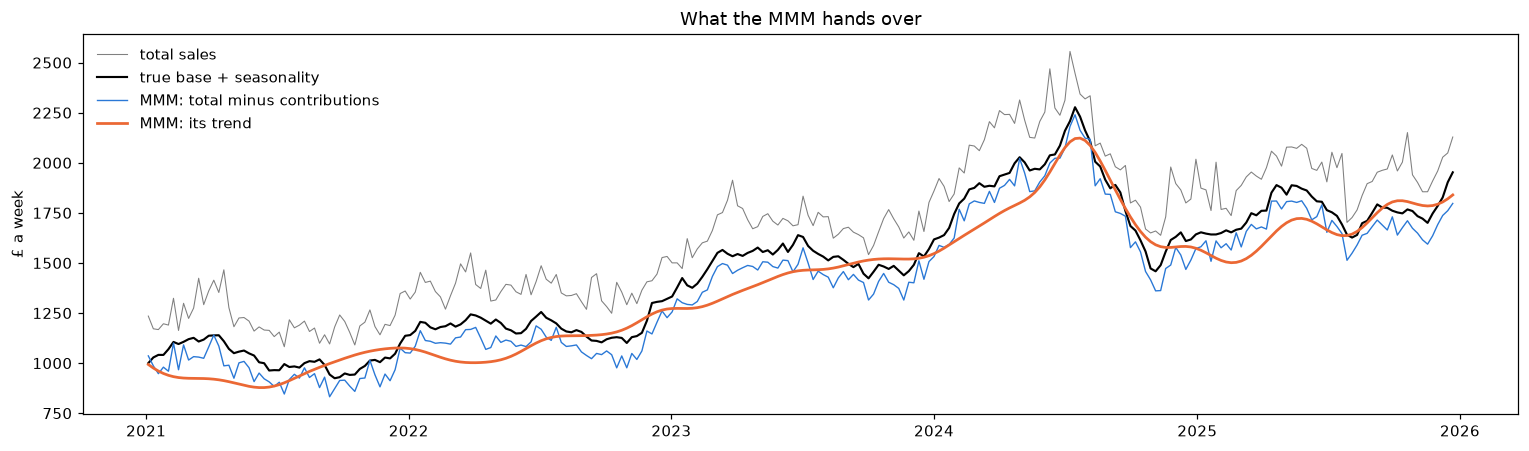

Trend lengthscale, posterior median: 40 weeks


,change autocorrelation,change sd (%)
true base,0.35,1.86
MMM: total minus contributions,-0.27,4.19
MMM: its trend,0.98,0.87


In [6]:
control = mmm_mean("control_contribution").sum("control").to_numpy()
minus = total - channels.sum("channel").to_numpy() - control  # seasonality kept
trend = pd.Series(mmm_mean("intercept_contribution").to_numpy(), index=total.index)
bases = {"true_base": parts["base"], "mmm_minus": minus, "mmm_trend": trend}

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(total.index, total, color="grey", lw=0.7, label="total sales")
ax.plot(
    total.index,
    parts["base"] + parts["seasonality"],
    color="black",
    lw=1.4,
    label="true base + seasonality",
)
ax.plot(total.index, minus, color=COLOURS["mmm_minus"], lw=0.9, label=LABELS["mmm_minus"])
ax.plot(total.index, trend, color=COLOURS["mmm_trend"], lw=1.8, label=LABELS["mmm_trend"])
ax.set_ylabel("£ a week")
ax.set_title("What the MMM hands over")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

rows = {}
for arm, series in bases.items():
    changes = np.log(series).diff().dropna()
    rows[LABELS[arm]] = {
        "change autocorrelation": changes.autocorr(),
        "change sd (%)": 100 * changes.std(),
    }
print(
    f"Trend lengthscale, posterior median: "
    f"{float(post['intercept_latent_process_raw_ls'].median()):.0f} weeks"
)
pd.DataFrame(rows).T.round(2)

**Reading the chart and table.**

- **Total minus contributions follows the true base,** with the noise and the seasonality still in it. Its weekly changes are noisy (4.2% against the true base's 1.9%) and negatively autocorrelated, as in guide 06.
- **The trend is a smooth curve through the middle.** Its weekly changes autocorrelate at 0.98: each week's move is almost the same as the last. The prior said 78 weeks and the data pulled the lengthscale down to 40, so the MMM wanted a more flexible trend, but even at 40 weeks it smooths away everything the brand system does from week to week. It also lags the turns: the 2024 peak and the 2025 dip both arrive late and flattened.

## 4. Four VECMs

Each with rank 2, one lag and `"co"`, the five brand drivers in levels:

- **True base:** the oracle.
- **MMM minus contributions:** the seasonal harmonics in the sales equation, as in guide 06.
- **MMM trend:** nothing extra; the trend has no seasonality in it.
- **One step:** log total sales, with brand spend, paid search, paid social, promo and the harmonics in the sales equation as weekly changes. The three channels get the VECM's own `adstock=`. The VECM is linear in them, so it cannot fit saturation.

In [7]:
FIT = {
    "draws": DRAWS,
    "tune": TUNE,
    "chains": CHAINS,
    "target_accept": 0.9,
    "random_seed": 14,
    "progressbar": False,
}


def harmonics(index, n=2):
    angle = 2 * np.pi * np.arange(len(index)) / PERIOD
    cols = {}
    for h in range(1, n + 1):
        cols[f"sin{h}"] = np.sin(h * angle)
        cols[f"cos{h}"] = np.cos(h * angle)
    return pd.DataFrame(cols, index=index)


def in_sales_equation(short_run):
    # Weekly changes, in the sales equation only.
    changes = short_run.diff()
    changes.columns = [f"d_{c}" for c in changes.columns]
    excluded = {AWARE: list(changes.columns), CONS: list(changes.columns)}
    return pd.concat([exog, changes], axis=1), excluded


def fit(sales, short_run=None, adstock=None):
    fit_endog = endog.copy()
    fit_endog[SALES] = np.log(sales)
    fit_exog, kwargs = exog.copy(), {}
    if short_run is not None:
        fit_exog, kwargs["excluded"] = in_sales_equation(short_run)
    if adstock:
        kwargs["adstock"] = adstock
    return BayesianVECM(**SPEC, **kwargs).fit(fit_endog.iloc[1:], exog=fit_exog.iloc[1:], **FIT)


models = {}

In [8]:
models["true_base"] = fit(parts["base"])

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


In [9]:
models["mmm_minus"] = fit(minus, harmonics(total.index))

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B_raw]


In [10]:
models["mmm_trend"] = fit(trend)

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


In [11]:
short_run = pd.concat([exog[["brand_spend"]], data.sales_drivers, harmonics(total.index)], axis=1)
models["one_step"] = fit(
    total, short_run, adstock=["d_brand_spend", "d_paid_search", "d_paid_social"]
)
bases["one_step"] = total

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, adstock_alpha, B_total_raw, B_free_raw]


In [12]:
for arm, model in models.items():
    s = model.summary().apply(pd.to_numeric, errors="coerce")
    print(
        f"{LABELS[arm]:<38} divergences {int(model.idata_.sample_stats['diverging'].sum())}, "
        f"max r-hat {s['r_hat'].max():.3f}, min bulk ESS {s['ess_bulk'].min():.0f}"
    )

true base                              divergences 0, max r-hat 1.007, min bulk ESS 998


MMM: total minus contributions         divergences 0, max r-hat 1.006, min bulk ESS 886


MMM: its trend                         divergences 0, max r-hat 1.003, min bulk ESS 1587


one step: total sales into the VECM    divergences 0, max r-hat 1.009, min bulk ESS 393


In [13]:
HORIZON = 260


def true_response(steps):
    pi = truth.alpha @ truth.beta.T
    y_, dy, out = np.zeros(3), np.zeros(3), []
    for h in range(steps + 1):
        dy = pi @ y_ + truth.gamma @ dy + (truth.b[:, 0] if h == 0 else 0.0)
        y_ = y_ + dy
        out.append(y_[0])
    return np.array(out)


true_path = true_response(HORIZON) * float(parts["base"].iloc[-52:].mean())


def describe(x, fmt="{:,.0f}"):
    lo, hi = np.percentile(x, TAILS)
    return f"{fmt.format(np.median(x))} ({fmt.format(lo)} to {fmt.format(hi)})"


paths, rows = {}, {}
for arm, model in models.items():
    irf = model.exog_irf(HORIZON).sel(response_variable=SALES, exog_variable="brand_spend")
    irf = irf.stack(sample=("chain", "draw")).transpose("sample", ...).values
    paths[arm] = irf * float(bases[arm].iloc[-52:].mean())
    vecm_post = model.idata_.posterior
    causality = model.granger_causality()
    leads = pd.concat([causality.short_run, causality.long_run])
    leads = leads[leads["cause"] == SALES]
    rows[LABELS[arm]] = {
        "permanent lift, £ a week": describe(paths[arm][:, -1]),
        "lift at week 4, £ a week": describe(paths[arm][:, 4]),
        "alpha (sales)": describe(vecm_post["alpha"].values[..., 0, 0].ravel(), "{:.2f}"),
        "sales leads a brand metric": bool((leads["evidence"] >= 0.95).any()),
    }
print(
    f"Truth: permanent lift £{true_path[-1]:,.0f} a week, at week 4 £{true_path[4]:,.0f}, "
    f"alpha {truth.alpha[0, 0]:.2f}"
)
pd.DataFrame(rows).T

Truth: permanent lift £39 a week, at week 4 £21, alpha -0.24


,"permanent lift, £ a week","lift at week 4, £ a week",alpha (sales),sales leads a brand metric
true base,44 (33 to 57),18 (5 to 31),-0.23 (-0.30 to -0.17),False
MMM: total minus contributions,45 (35 to 57),21 (9 to 33),-0.53 (-0.63 to -0.43),False
MMM: its trend,70 (52 to 97),13 (7 to 19),-0.01 (-0.01 to -0.00),True
one step: total sales into the VECM,44 (34 to 55),23 (10 to 36),-0.42 (-0.51 to -0.32),False


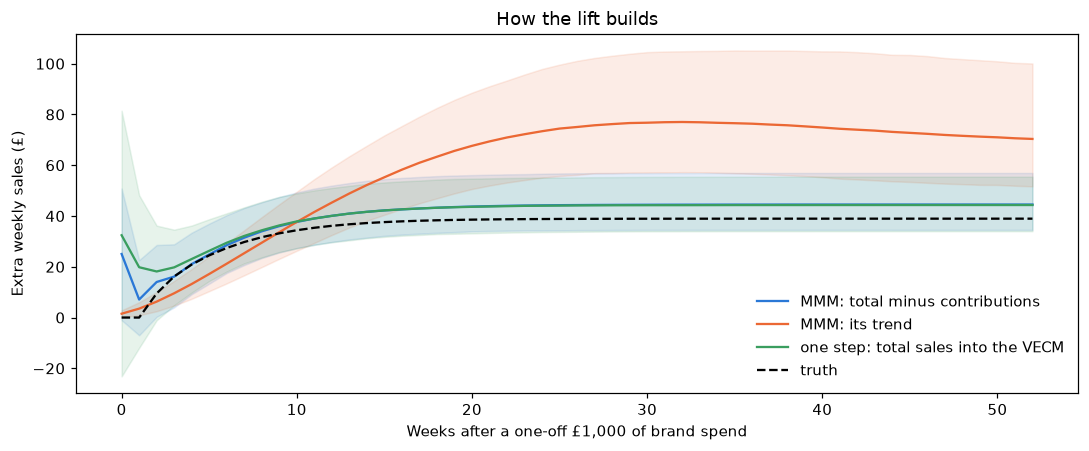

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
weeks = np.arange(53)
for arm in ["mmm_minus", "mmm_trend", "one_step"]:
    lo, med, hi = np.percentile(paths[arm][:, :53], [TAILS[0], 50, TAILS[1]], axis=0)
    ax.fill_between(weeks, lo, hi, color=COLOURS[arm], alpha=0.12)
    ax.plot(weeks, med, color=COLOURS[arm], label=LABELS[arm])
ax.plot(weeks, true_path[:53], color="black", ls="--", label="truth")
ax.set_xlabel("Weeks after a one-off £1,000 of brand spend")
ax.set_ylabel("Extra weekly sales (£)")
ax.set_title("How the lift builds")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Reading the table and chart.**

- **Total minus contributions and the one-step VECM** give the same return as the fit on the true base (£44 to £45 a week, against £44 on the true base and a truth of £39), and the lift builds at the right pace. Both have the fast `alpha` that noise in the base produces (guide 06).
- **The trend gets it wrong on this data set:** £70 a week, with an interval that misses the truth. Its `alpha` is close to zero, so sales hardly close a gap to consideration at all. The lift builds slowly and overshoots. The direction tests find sales leading a brand metric, a link the truth does not have. A smooth series that lags the turns looks, to a Granger test, like a series that is driven and drives at once.

## 5. Is one data set enough?

No. `tools/mmm_trend_check.py` repeats this on 5 data sets, at three prior lengthscales for the MMM trend (26, 78 and 156 weeks) and with one more MMM base: minus the seasonal contribution as well. It also runs guide 06's UCM recipe, which is now misspecified. The table shows the median error against the truth and, for the permanent lift, the share of 90% intervals that contain it. `false direction` counts fits that find sales leading awareness or consideration with evidence of 0.95 or more; the truth has no such link.

In [15]:
runs = pd.read_csv(ROOT / "tools" / "mmm_trend_check_results.csv", dtype={"arm": str})
order = [
    "true_base",
    "ucm_keep_season",
    "total_adstock",
    *(f"mmm{ls}_{k}" for ls in (26, 78, 156) for k in ("keep_season", "minus", "trend")),
]
names = {
    "true_base": "true base",
    "ucm_keep_season": "UCM recipe (no carryover or saturation)",
    "total_adstock": "one step: total sales into the VECM",
}
for ls in (26, 78, 156):
    names[f"mmm{ls}_keep_season"] = f"MMM {ls} wk: minus contributions, seasonal kept"
    names[f"mmm{ls}_minus"] = f"MMM {ls} wk: minus contributions and seasonal"
    names[f"mmm{ls}_trend"] = f"MMM {ls} wk: trend"
runs["error"] = runs["median"] / runs["truth"] - 1
errors = runs.pivot_table(index="arm", columns="quantity", values="error", aggfunc="median")
coverage = runs[runs["quantity"] == "lift_permanent"].groupby("arm")["covered"].mean()
first = runs.drop_duplicates(["seed", "arm"]).copy()
evidence_cols = [c for c in runs.columns if c.startswith("evidence_sales_to")]
first["false_direction"] = first[evidence_cols].max(axis=1) >= 0.95
table = pd.DataFrame(
    {
        "permanent lift": errors["lift_permanent"].map("{:+.0%}".format),
        "coverage": coverage.map("{:.0%}".format),
        "week-4 lift": errors["lift_week4"].map("{:+.0%}".format),
        "alpha": errors["alpha_sales"].map("{:+.0%}".format),
        "false direction": first.groupby("arm")["false_direction"].sum().astype(int).astype(str)
        + " of 5",
    }
).reindex(order)
table.index = [names[a] for a in table.index]
print("Median error against the truth, 5 data sets")
table

Median error against the truth, 5 data sets


,permanent lift,coverage,week-4 lift,alpha,false direction
true base,-0%,100%,-5%,+9%,0 of 5
UCM recipe (no carryover or saturation),-2%,80%,+2%,+116%,1 of 5
one step: total sales into the VECM,-3%,80%,+30%,+52%,0 of 5
"MMM 26 wk: minus contributions, seasonal kept",+1%,100%,+2%,+98%,0 of 5
MMM 26 wk: minus contributions and seasonal,-3%,100%,-10%,+32%,0 of 5
MMM 26 wk: trend,+2%,80%,-78%,-92%,5 of 5
"MMM 78 wk: minus contributions, seasonal kept",+1%,100%,+3%,+97%,0 of 5
MMM 78 wk: minus contributions and seasonal,-2%,100%,-17%,+9%,0 of 5
MMM 78 wk: trend,+3%,80%,-68%,-94%,4 of 5
"MMM 156 wk: minus contributions, seasonal kept",+0%,100%,+4%,+96%,0 of 5


**Reading the table.**

- **The long-run return is again robust.** Every arm is within 3% of the truth in the median, the trend included. On this data set the trend was the exception; across five it has the widest intervals (65% to 80% of the truth against 46% for the true base) and 80% coverage.
- **The trend fails the short run at every lengthscale.** `alpha` is 92% to 95% too slow, the lift at week 4 is 62% to 78% too low and 4 or 5 of 5 fits find a direction link that is not there. A longer or shorter prior lengthscale does not fix it.
- **Total minus contributions with the seasonality kept** is the best two-stage route: the lift at week 4 within 4% at every lengthscale. Taking the MMM's seasonal estimate out as well makes the lift 10% to 18% too slow, as in guide 06.
- **The one-step VECM** gets the return and the direction tests right but the lift builds 30% too fast. It is linear in spend, so it cannot fit saturation: it spreads the same effect over the weeks differently.
- **Guide 06's UCM recipe** still gets the return, although it ignores carryover and saturation. Its timing is right here too, but it has no way to represent the short-term media correctly, so its contributions should not be read.
- **Only five data sets.** The directions are the same in every data set; the sizes are rough.

## 6. What this means

- **Never give the VECM an MMM's trend as base sales.** It gets the long-run return roughly right on average, but with wide intervals and a bad miss on some data sets. Everything short-run comes out wrong, and its direction tests find links that are not there. This holds at every lengthscale tried. Most MMM tools report this trend as their "baseline", so ask how the base was made.
- **Use total sales minus the MMM's contributions,** with the seasonality kept in and the seasonal terms in the VECM's sales equation. It behaves like the UCM base of guide 06: the right return and the right timing.
- **Or skip the MMM.** Total sales straight into the VECM gets the return right with no false direction findings. It needs the short-term drivers entered as weekly changes, and it cannot fit saturation, so the lift's shape in the first weeks is off. It is a good check on the two-stage result, and the simpler route when no MMM exists.
- **The MMM still needs care.** With PyMC-Marketing's default priors the fit here was not identified: a negative intercept, with two channels worth about £3,400 a week each against total sales of £1,700. Positive priors on the intercept and tight priors on the channel coefficients fixed it. Check the MMM's contributions against what the business knows before using its base.

**Not covered yet.** Other MMM tools (Meridian, Robyn), other kinds of trend (splines, random walks), seasonal brand metrics and holiday spikes.